# 01 · Exploratory Data Analysis — ABC Credit Loan Approval

**Goal:** understand `data/training_data.csv` before modelling: schema, target balance, distributions,
relationship of each field to the target, and data-quality issues.

Everything is read **as strings first** so that nothing is silently coerced — type problems are themselves findings.
Cleaning rules derived here are implemented in `src/loan_model/cleaning.py` and applied in notebook 02.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from loan_model import config as C

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", palette="deep")
FIG = C.FIGURES_DIR; FIG.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight"); plt.show()

## 1. Load & schema

In [2]:
raw = pd.read_csv(C.RAW_DATA, dtype=str)
print(raw.shape)
raw.head()

(108423, 17)


,ID,Qualifications,Employment_Type,Age,Pincode,Gender,Product_Code,Loan_Amount,LTV,Resident_Type,Net_salary,Final_Tier,Make_Code,Model_Description,Model_Variant,PAST_LOANS_ACTIVE,Decision
0,1,SSC,AGR,47,502110,Male,MO,59300,69.76,O,39000,07 Rural,MOPEDS,TVS XL 100 HD ITS BSVI - WINNER EDITION,XL 100CC,PAST_LOANS_ACTIVE,APPROVED
1,2,UG,SAL,30,503002,Male,MC,153839,84.99,O,25000,05 Urban,APACHE,APACHE 200 4V 2CH - R MODE BSVI,RTR 200CC,PAST_LOANS_ACTIVE,APPROVED
2,3,GRAD,NREGI,24,500090,Male,SC,77958,64.97,R,35000,04 Metro,JUPITER,JUPITER ZX BSVI - AOL - DRUM,110 CC,PAST_LOANS_ACTIVE,APPROVED
3,4,UG,SAL,44,501141,Male,SC,99921,84.68,O,25000,07 Rural,JUPITER,JUPITER 125 BSVI - DISC,125 CC DISC,PAST_LOANS_ACTIVE,APPROVED
4,5,SSC,SAL,41,509334,Male,SC,96482,75.38,O,35000,07 Rural,JUPITER,JUPITER 125 BSVI DISC SXC U566,125CC DISC,PAST_LOANS_ACTIVE,APPROVED


In [3]:
schema = pd.DataFrame({
    "non_null": raw.notna().sum(),
    "nulls": raw.isna().sum(),
    "null_%": (raw.isna().mean() * 100).round(3),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
})
schema

,non_null,nulls,null_%,n_unique,example
ID,108422,1,0.001,108422,1
Qualifications,108397,26,0.024,6,SSC
Employment_Type,108395,28,0.026,8,AGR
Age,108404,19,0.018,53,47
Pincode,108422,1,0.001,13999,502110
Gender,108422,1,0.001,2,Male
Product_Code,108422,1,0.001,4,MO
Loan_Amount,108422,1,0.001,52527,59300
LTV,108422,1,0.001,6619,69.76
Resident_Type,108403,20,0.018,3,O


## 2. Target balance

,count,share_%
Decision,,
APPROVED,102724,94.74
DECLINED,5698,5.26
NaN,1,0.00


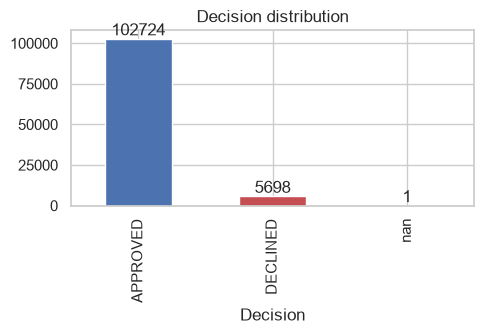

DECLINED base rate: 5.26%  -> a model that always says APPROVED is 94.7% 'accurate'


In [4]:
tgt = raw["Decision"].value_counts(dropna=False)
display(pd.DataFrame({"count": tgt, "share_%": (tgt / tgt.sum() * 100).round(2)}))
ax = tgt.dropna().plot.bar(color=["#4C72B0", "#C44E52"], figsize=(5, 3.5), title="Decision distribution")
ax.bar_label(ax.containers[0]); savefig("01_target_balance")
base_rate = (raw["Decision"] == "DECLINED").mean()
print(f"DECLINED base rate: {base_rate:.2%}  -> a model that always says APPROVED is {1-base_rate:.1%} 'accurate'")

**Finding — severe imbalance (~5% DECLINED).** Plain accuracy is meaningless here (the all-APPROVE model scores ~95%).
Consequences for the rest of the project:
* Evaluate with **ROC-AUC / PR-AUC** for ranking quality, and **precision / recall / F1 on the DECLINED class** at a chosen threshold.
* Use **stratified** splits and CV.
* Pick the approve/decline cut-off from a **business cost trade-off**, not the default 0.5.

## 3. Data-quality audit

### 3.1 Missing values & blank rows

In [5]:
empty_rows = raw[raw.drop(columns=["Age"]).isna().all(axis=1)]
print("Rows with (almost) every field empty:", len(empty_rows))
display(empty_rows)
print("Age values that are not numbers:", raw.loc[pd.to_numeric(raw.Age, errors="coerce").isna() & raw.Age.notna(), "Age"].map(repr).value_counts().to_dict())

Rows with (almost) every field empty: 1


,ID,Qualifications,Employment_Type,Age,Pincode,Gender,Product_Code,Loan_Amount,LTV,Resident_Type,Net_salary,Final_Tier,Make_Code,Model_Description,Model_Variant,PAST_LOANS_ACTIVE,Decision
108422,NaN,NaN,NaN,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Age values that are not numbers: {"' '": 1}


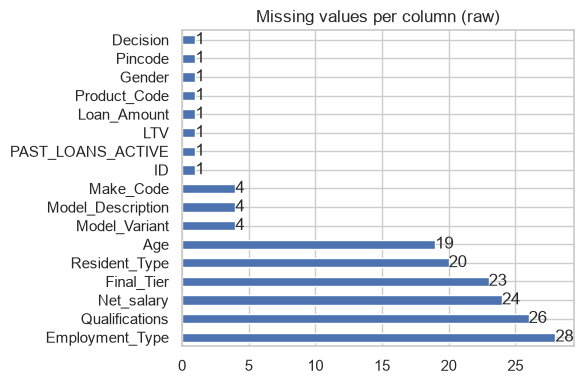

In [6]:
miss = raw.isna().sum().sort_values(ascending=False)
miss = miss[miss > 0]
ax = miss.plot.barh(figsize=(6, 4), title="Missing values per column (raw)"); ax.bar_label(ax.containers[0]); savefig("02_missing_values")

### 3.2 Duplicates

In [7]:
feat_cols = [c for c in raw.columns if c not in ("ID", "Decision")]
print("Duplicate IDs:", raw.ID.dropna().duplicated().sum())
print("Fully duplicated rows:", raw.duplicated().sum())
print("Duplicated rows ignoring ID (same applicant record re-entered):", raw.drop(columns="ID").duplicated().sum())
print("Same features but CONFLICTING decision:", raw[raw.duplicated(subset=feat_cols, keep=False)].groupby(feat_cols, dropna=False).Decision.nunique().gt(1).sum())

Duplicate IDs: 0


Fully duplicated rows: 0
Duplicated rows ignoring ID (same applicant record re-entered): 13
Same features but CONFLICTING decision: 3


### 3.3 Numeric fields: ranges and impossible values

In [8]:
num = raw[["Age", "Loan_Amount", "LTV", "Net_salary"]].apply(pd.to_numeric, errors="coerce")
display(num.describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).T.round(2))
checks = {
    "Age > 60 (outside 18-60 policy)": (num.Age > C.POLICY_AGE_MAX).sum(),
    "Age < 18": (num.Age < C.POLICY_AGE_MIN).sum(),
    "LTV == 0 (impossible for a financed vehicle)": (num.LTV == 0).sum(),
    "LTV > 100": (num.LTV > 100).sum(),
    "Net_salary == 0": (num.Net_salary == 0).sum(),
    "Net_salary < 5,000 / month": (num.Net_salary < 5000).sum(),
    "Net_salary > 2,00,000 / month": (num.Net_salary > 200000).sum(),
}
pd.Series(checks, name="rows").to_frame()

,count,mean,std,min,0.1%,1%,5%,50%,95%,99%,99.9%,max
Age,108403.0,34.43,10.73,18.0,18.00,19.00,21.00,32.00,55.00,61.00,64.00,69.0
Loan_Amount,108422.0,89289.26,25553.59,16569.0,26983.79,36459.21,48390.10,90075.00,131072.70,146024.79,175928.05,286847.0
LTV,108422.0,77.69,12.71,0.0,25.07,37.35,51.19,81.33,91.88,94.97,97.11,99.6
Net_salary,108399.0,33983.21,20183.72,0.0,0.00,15000.00,20000.00,30000.00,50000.00,85000.00,300000.00,980000.0


,rows
Age > 60 (outside 18-60 policy),1105
Age < 18,0
LTV == 0 (impossible for a financed vehicle),65
LTV > 100,0
Net_salary == 0,626
"Net_salary < 5,000 / month",887
"Net_salary > 2,00,000 / month",193


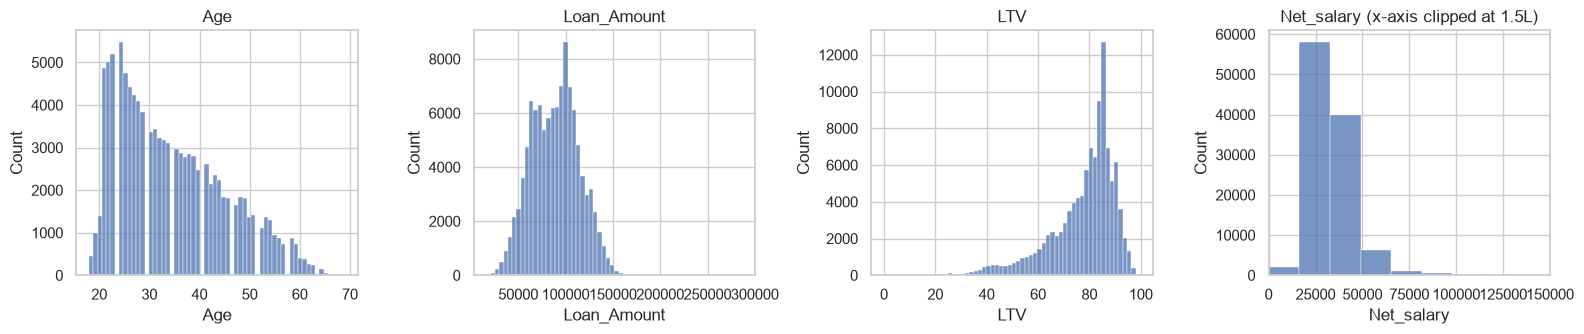

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, num.columns):
    sns.histplot(num[col].dropna(), bins=60, ax=ax); ax.set_title(col)
axes[3].set_xlim(0, 150000); axes[3].set_title("Net_salary (x-axis clipped at 1.5L)")
savefig("03_numeric_distributions")

In [10]:
print("Low salaries (< 5,000):"); display(num.Net_salary[num.Net_salary < 5000].value_counts().head(10))
print("Very high salaries (> 2L) – possibly annual figures entered as monthly:")
display(raw.loc[num.Net_salary > 200000, ["Employment_Type", "Net_salary", "Loan_Amount", "Product_Code", "Decision"]].head(10))
print("Rows with LTV == 0:"); display(raw.loc[num.LTV == 0, ["Loan_Amount", "LTV", "Product_Code", "Decision"]].head())

Low salaries (< 5,000):


Net_salary
0.0       626
100.0      43
3500.0     33
3000.0     32
2500.0     30
1.0        27
4000.0      9
4500.0      7
2000.0      7
2800.0      6
Name: count, dtype: int64

Very high salaries (> 2L) – possibly annual figures entered as monthly:


,Employment_Type,Net_salary,Loan_Amount,Product_Code,Decision
120,AGR,250000,72824,MC,APPROVED
759,NREGI,450000,129765,MC,APPROVED
1243,NREGI,350000,91379,MC,APPROVED
1464,SAL,258000,62796,MC,APPROVED
1985,SEP,325000,99307,MC,APPROVED
2016,SAL,250000,71500,SC,APPROVED
2611,SEP,250000,98519,SC,DECLINED
3280,SEP,320000,128525,MC,APPROVED
3505,SAL,250000,73912,MC,APPROVED
4411,SEP,850000,88706,SC,APPROVED


Rows with LTV == 0:


,Loan_Amount,LTV,Product_Code,Decision
231,122656,0,EB,APPROVED
232,101020,0,SC,APPROVED
793,100726,0,SC,APPROVED
794,71907,0,MC,APPROVED
1257,96243,0,SC,APPROVED


### 3.4 Categorical fields: inconsistent coding

In [11]:
for col in ["Qualifications", "Employment_Type", "Gender", "Product_Code", "Resident_Type",
            "Final_Tier", "Make_Code", "Model_Variant", "PAST_LOANS_ACTIVE"]:
    print(f"{col}: {raw[col].value_counts(dropna=False).to_dict()}")

Qualifications: {'OTHERS': 33018, 'HSC': 26790, 'GRAD': 20468, 'SSC': 11853, 'UG': 8432, 'PG': 7836, nan: 26}
Employment_Type: {'SEP': 38363, 'SAL': 33479, 'AGR': 21050, 'NREGI': 14102, 'STU': 753, 'NPP': 505, 'PEN': 135, nan: 28, 'NONEARNMEM': 8}
Gender: {'Male': 83034, 'Female': 25388, nan: 1}
Product_Code: {'MC': 51673, 'SC': 36819, 'MO': 16477, 'EB': 3453, nan: 1}
Resident_Type: {'O': 103129, 'R': 5114, 'L': 160, nan: 20}
Final_Tier: {'07 Rural': 72394, '06 Semi-Urban': 21509, '05 Urban': 6012, '02 Megapolis (B)': 3662, '04 Metro': 2859, '03 Large Metro': 1283, '01 Megapolis (A)': 681, nan: 23}
Make_Code: {'JUPITER': 21048, 'APACHE': 20354, 'RAIDER': 18771, 'MOPEDS': 16476, 'NTORQ': 12143, 'SPORT': 6115, 'RADEON': 5153, 'ZEST': 3618, 'TVS': 3452, 'CITY PLUS': 668, 'RONIN': 612, 'SCOOTY': 9, nan: 4}
Model_Variant: {'RAIDER': 18771, 'XL 100CC': 16476, '160 DISC': 16363, '125 CC': 12143, '110 CC': 11215, 'SPORT': 6115, 'RADEON': 5153, '125 CC DISC': 4852, 'SCOOTY': 3618, 'EBIKE': 3452

In [12]:
mojibake = raw.Model_Description[raw.Model_Description.str.contains("â", na=False)].value_counts()
print("Model descriptions with mis-decoded characters ('â€“' is a UTF-8 en dash read as cp1252):"); display(mojibake)
print("Same variant spelled two ways:", raw.Model_Variant[raw.Model_Variant.str.contains(r"\dCC", na=False)].unique().tolist(),
      "vs", raw.Model_Variant[raw.Model_Variant.str.contains(r"\d CC", na=False)].unique().tolist())

Model descriptions with mis-decoded characters ('â€“' is a UTF-8 en dash read as cp1252):


Model_Description
NTORQ 125 DISC â€“ RACE EDITION BSVI      4370
STARCITY PLUS ES DT BSVI â€“ DUAL TONE     514
JUPITER ZX BSVI â€“ ZX DRUM                103
STARCITY PLUS ES BSVI â€“ MONO TONE         41
Name: count, dtype: int64

Same variant spelled two ways: ['XL 100CC', 'RTR 200CC', '125CC DISC'] vs ['110 CC', '125 CC DISC', '125 CC', '125 CC DRUM', 'APACHE 180 CC', '165 CC']


### 3.5 Structural consistency between fields

In [13]:
print("Pincode -> Final_Tier: tiers per pincode")
print(raw.dropna(subset=["Final_Tier"]).groupby("Pincode").Final_Tier.nunique().value_counts().to_dict())
missing_tier = raw.Final_Tier.isna() & raw.Pincode.notna()
known = raw.dropna(subset=["Final_Tier"]).Pincode.unique()
print(f"Rows missing Final_Tier: {missing_tier.sum()}, of which pincode seen elsewhere with a tier: {raw.loc[missing_tier, 'Pincode'].isin(known).sum()}")
print("\nPincode format:", raw.Pincode.dropna().str.fullmatch(r"[1-9]\d{5}").value_counts().to_dict())
print("\nModel_Description -> Make_Code / Product_Code / Model_Variant (levels per description):")
print({c: raw.groupby("Model_Description")[c].nunique().max() for c in ["Make_Code", "Product_Code", "Model_Variant"]})
pd.crosstab(raw.Make_Code, raw.Product_Code)

Pincode -> Final_Tier: tiers per pincode
{1: 13981}
Rows missing Final_Tier: 22, of which pincode seen elsewhere with a tier: 0

Pincode format: {True: 108422}

Model_Description -> Make_Code / Product_Code / Model_Variant (levels per description):
{'Make_Code': np.int64(1), 'Product_Code': np.int64(1), 'Model_Variant': np.int64(1)}


Product_Code,EB,MC,MO,SC
Make_Code,,,,
APACHE,0,20354,0,0
CITY PLUS,0,668,0,0
JUPITER,0,0,0,21048
MOPEDS,0,0,16476,0
NTORQ,0,0,0,12143
RADEON,0,5153,0,0
RAIDER,0,18771,0,0
RONIN,0,612,0,0
SCOOTY,0,0,0,9


**Data-quality findings (handled in `cleaning.py` / `features.py`):**

| # | Issue | Evidence | Treatment |
|---|---|---|---|
| 1 | Fully blank trailing row (no ID, no target) | 1 row | Drop |
| 2 | `Age` contains a blank string `' '` | 1 row | Coerce to NaN → imputed by model |
| 3 | Duplicate application records with different IDs | 13 rows (3 with conflicting decisions) | Drop exact duplicates (keep first); conflicting pairs kept – label noise the model must tolerate |
| 4 | `LTV == 0` – impossible for a financed loan | 65 rows | Set NaN + `ltv_missing` flag |
| 5 | `Net_salary` 0 or < ₹5,000/month | ~890 rows | Set NaN (implausible) |
| 6 | `Net_salary` extreme (up to ₹9.8L/month; likely annual) | ~190 rows > ₹2L | Winsorise at the 99.5th pct, learned on train |
| 7 | `Age` > 60 – outside lending policy (max 69) | ~1,100 rows | Kept for training (they are real decisions); the chatbot enforces 18–60 as a hard eligibility rule |
| 8 | Mojibake in `Model_Description` (`â€“`) | 4 descriptions | Fix encoding, normalise whitespace/dashes |
| 9 | Same variant spelled two ways (`125CC DISC` / `125 CC DISC`, `XL 100CC`, `RTR 200CC`) | 3 variants | Normalise `NNN CC` |
| 10 | Missing categoricals (Qualifications, Employment, Resident, Tier, Make…) | 4–28 rows each | `UNKNOWN` category; `Final_Tier` filled from the pincode→tier map, falling back to the 3-digit pincode prefix (the 22 affected pincodes never appear elsewhere) |
| 11 | Rare categories (`NONEARNMEM`=8, `SCOOTY`=9, `165 CC`=1) | | Grouped as infrequent by the encoder (min frequency 20) |
| 12 | Unseen categories at scoring time | brief | All encoders use `handle_unknown` → never break |

## 4. Relationship of each field to the target

In [14]:
df = raw.dropna(subset=["Decision"]).copy()
df["declined"] = (df.Decision == "DECLINED").astype(int)
for c in ["Age", "Loan_Amount", "LTV", "Net_salary"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df.loc[df.LTV == 0, "LTV"] = np.nan
df.loc[df.Net_salary < 5000, "Net_salary"] = np.nan
df["vehicle_value"] = df.Loan_Amount / (df.LTV / 100)
df["loan_to_income"] = df.Loan_Amount / df.Net_salary
base = df.declined.mean()

### 4.1 Categorical fields — decline rate by level

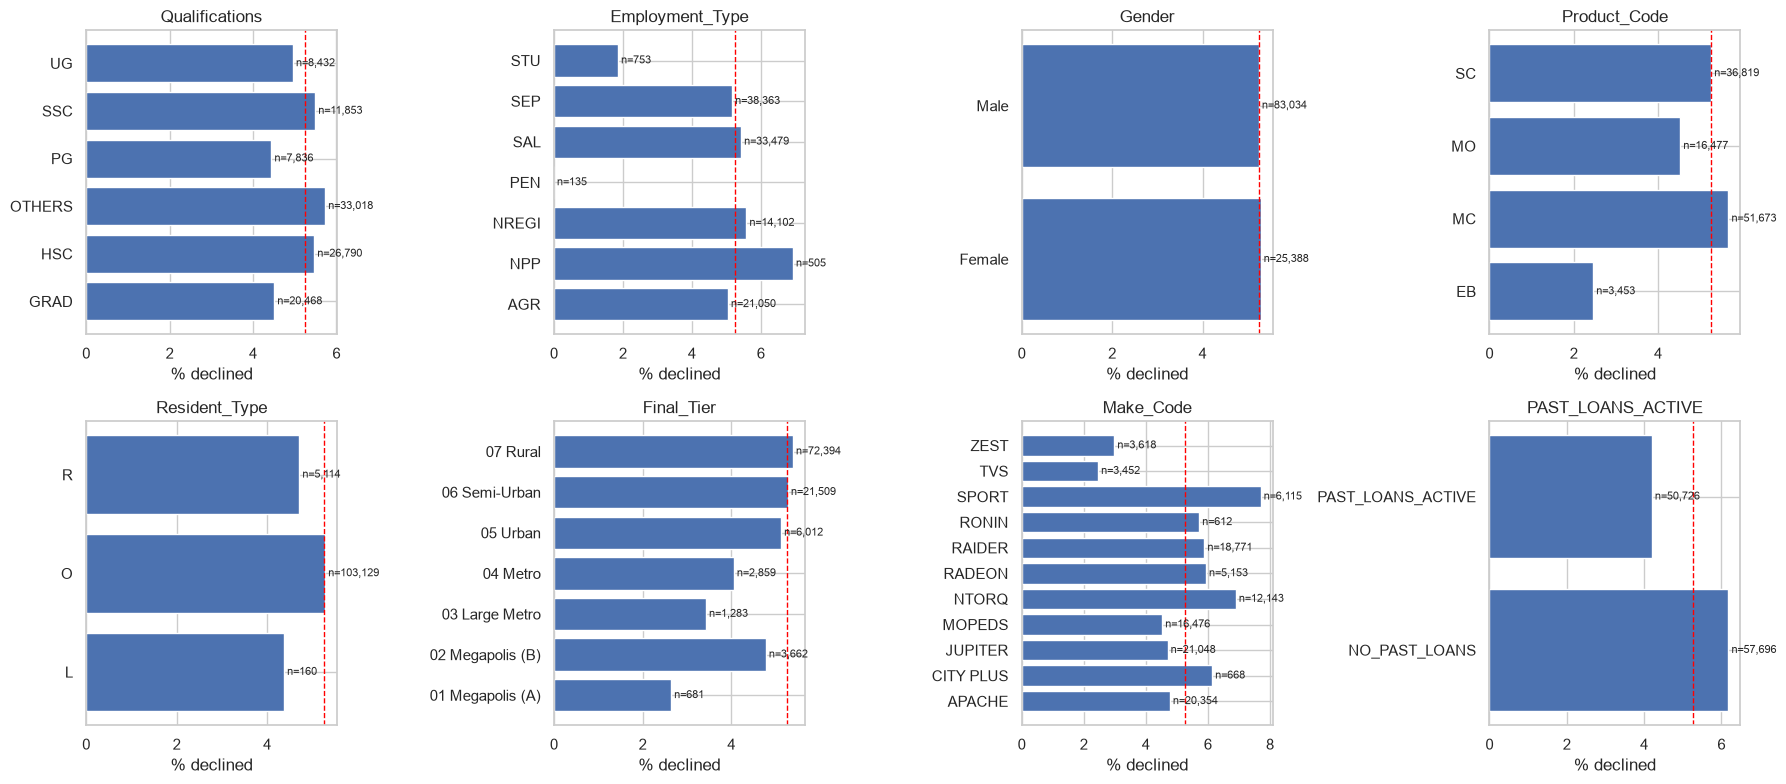

In [15]:
cats = ["Qualifications", "Employment_Type", "Gender", "Product_Code", "Resident_Type",
        "Final_Tier", "Make_Code", "PAST_LOANS_ACTIVE"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, cats):
    g = df.groupby(df[c].fillna("NA")).declined.agg(["mean", "size"]).sort_index()
    g = g[g["size"] >= 30]
    ax.barh(g.index.astype(str), g["mean"] * 100)
    ax.axvline(base * 100, color="red", ls="--", lw=1)
    ax.set_title(c); ax.set_xlabel("% declined")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m * 100, i, f" n={n:,}", va="center", fontsize=8)
savefig("04_categorical_decline_rates")

To compare fields on one scale we use **mutual information** with the target (categoricals as-is, numerics binned
into deciles) and **univariate ROC-AUC** for numerics.

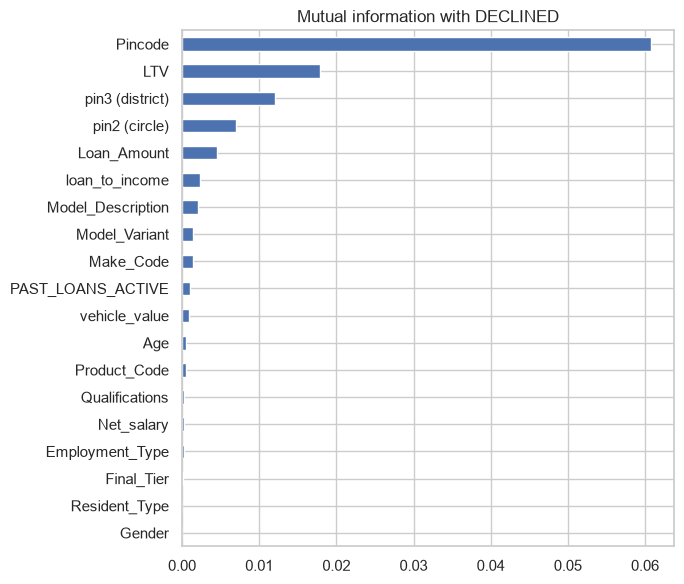

Note: raw MI of very high-cardinality fields (Pincode: 14k levels) is inflated by chance – compare at pin2/pin3 level.


,univariate ROC-AUC
Age,0.461
Loan_Amount,0.613
LTV,0.736
Net_salary,0.508
vehicle_value,0.506
loan_to_income,0.580


In [16]:
from sklearn.metrics import mutual_info_score, roc_auc_score
mi = {}
for c in cats + ["Model_Variant", "Model_Description", "Pincode"]:
    mi[c] = mutual_info_score(df.declined, df[c].fillna("NA"))
df["pin3"] = df.Pincode.str[:3]; df["pin2"] = df.Pincode.str[:2]
mi["pin3 (district)"] = mutual_info_score(df.declined, df.pin3.fillna("NA"))
mi["pin2 (circle)"] = mutual_info_score(df.declined, df.pin2.fillna("NA"))
for c in ["Age", "Loan_Amount", "LTV", "Net_salary", "vehicle_value", "loan_to_income"]:
    mi[c] = mutual_info_score(df.declined, pd.qcut(df[c], 10, duplicates="drop").cat.codes)
mi = pd.Series(mi).sort_values()
ax = mi.plot.barh(figsize=(7, 6), title="Mutual information with DECLINED"); savefig("05_mutual_information")
print("Note: raw MI of very high-cardinality fields (Pincode: 14k levels) is inflated by chance – compare at pin2/pin3 level.")
uni_auc = {c: roc_auc_score(df.declined[df[c].notna()], df[c].dropna()) for c in ["Age", "Loan_Amount", "LTV", "Net_salary", "vehicle_value", "loan_to_income"]}
pd.Series(uni_auc, name="univariate ROC-AUC").round(3).to_frame()

### 4.2 Numeric fields — decline rate by decile

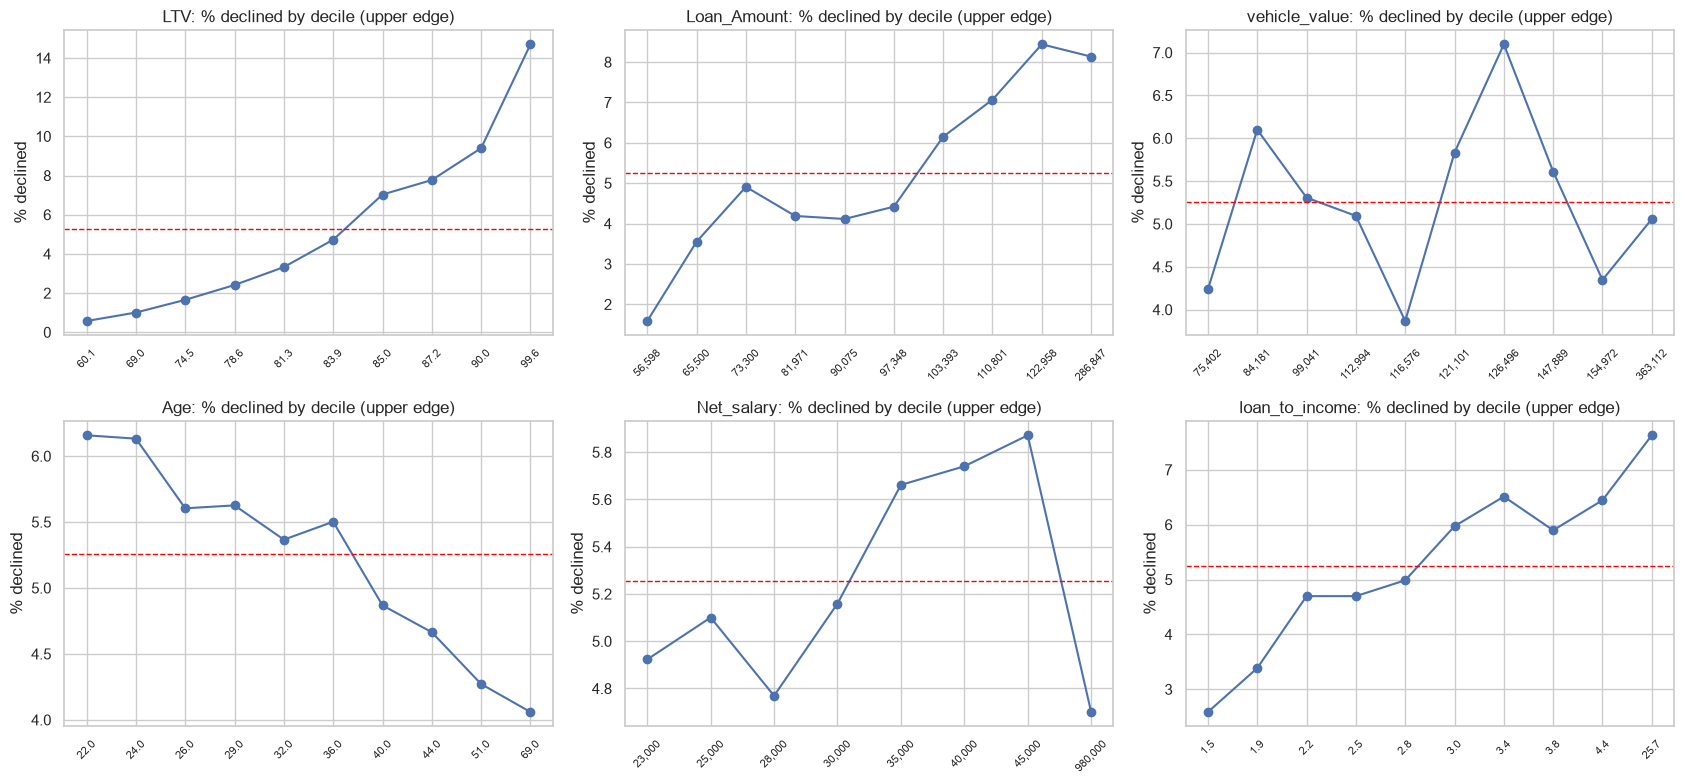

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, c in zip(axes.flat, ["LTV", "Loan_Amount", "vehicle_value", "Age", "Net_salary", "loan_to_income"]):
    b = pd.qcut(df[c], 10, duplicates="drop")
    g = df.groupby(b, observed=True).declined.mean() * 100
    ax.plot(range(len(g)), g.values, marker="o"); ax.axhline(base * 100, color="red", ls="--", lw=1)
    ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{i.right:,.0f}" if i.right > 100 else f"{i.right:.1f}" for i in g.index], rotation=45, fontsize=8)
    ax.set_title(f"{c}: % declined by decile (upper edge)"); ax.set_ylabel("% declined")
savefig("06_numeric_decline_by_decile")

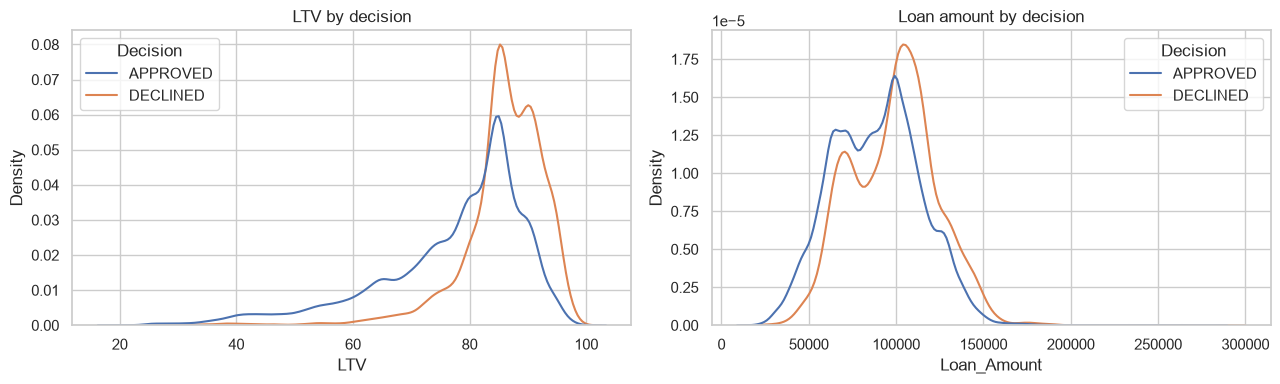

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=df, x="LTV", hue="Decision", common_norm=False, ax=ax[0]); ax[0].set_title("LTV by decision")
sns.kdeplot(data=df, x="Loan_Amount", hue="Decision", common_norm=False, ax=ax[1]); ax[1].set_title("Loan amount by decision")
savefig("07_ltv_loan_kde")

### 4.3 Geography

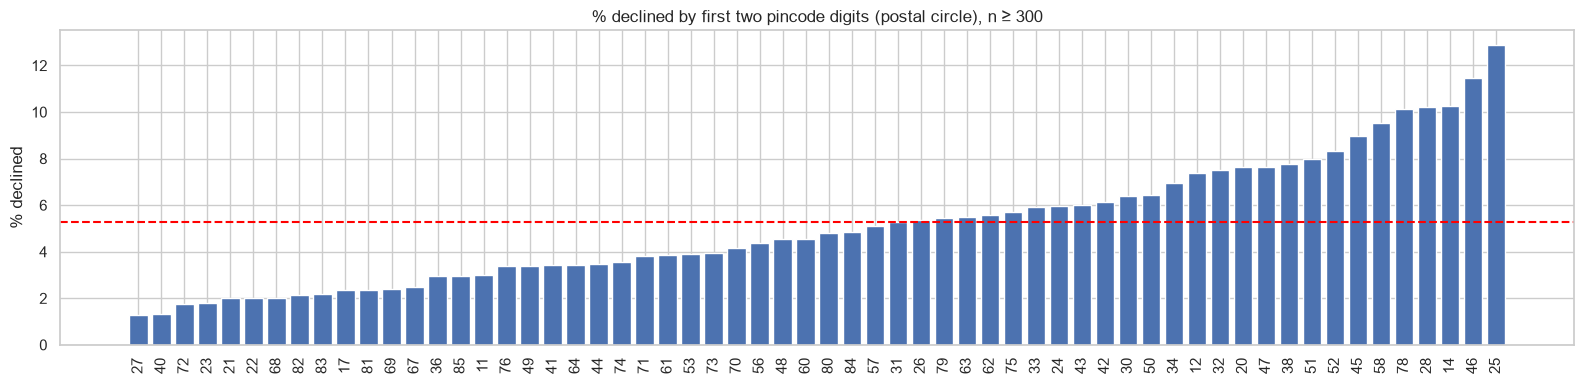

Decline rate ranges from 1.3% to 12.9% across postal circles – a strong regional effect.


In [19]:
g = df.groupby("pin2").declined.agg(["mean", "size"]).query("size >= 300").sort_values("mean")
fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(g.index, g["mean"] * 100); ax.axhline(base * 100, color="red", ls="--")
ax.set_title("% declined by first two pincode digits (postal circle), n ≥ 300"); ax.set_ylabel("% declined"); plt.xticks(rotation=90)
savefig("08_decline_by_pincode_prefix")
print(f"Decline rate ranges from {g['mean'].min():.1%} to {g['mean'].max():.1%} across postal circles – a strong regional effect.")

### 4.4 Interactions

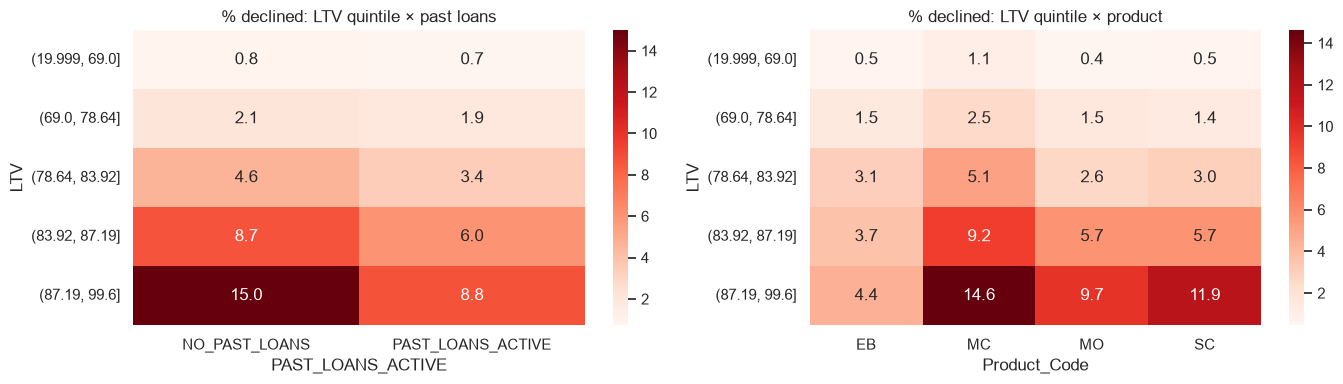

In [20]:
pv = df.pivot_table(index=pd.qcut(df.LTV, 5), columns="PAST_LOANS_ACTIVE", values="declined", aggfunc="mean", observed=True) * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(pv, annot=True, fmt=".1f", cmap="Reds", ax=ax[0]); ax[0].set_title("% declined: LTV quintile × past loans")
pv2 = df.pivot_table(index=pd.qcut(df.LTV, 5), columns="Product_Code", values="declined", aggfunc="mean", observed=True) * 100
sns.heatmap(pv2, annot=True, fmt=".1f", cmap="Reds", ax=ax[1]); ax[1].set_title("% declined: LTV quintile × product")
savefig("09_interactions")

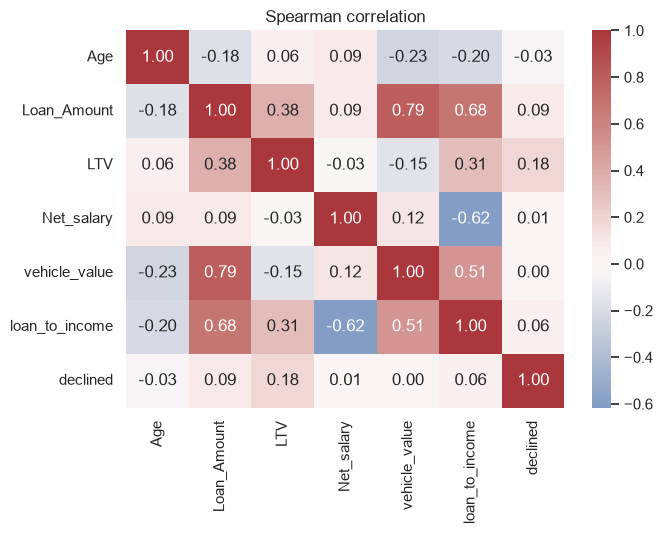

In [21]:
corr = df[["Age", "Loan_Amount", "LTV", "Net_salary", "vehicle_value", "loan_to_income", "declined"]].corr(method="spearman")
plt.figure(figsize=(7, 5.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0); plt.title("Spearman correlation")
savefig("10_numeric_correlation")

## 5. Summary of EDA findings

**Target.** ~5.3% DECLINED → imbalanced; use ranking metrics + class-specific precision/recall, stratified CV, cost-based threshold.

**Strongest signals**
1. **LTV** is by far the strongest single predictor: decline rate rises monotonically from <1% (LTV ≤ 60) to ~15% (LTV > 90).
   Higher loan amount / vehicle value also raises risk (they overlap with LTV).
2. **Geography (pincode)**: decline rates differ several-fold between postal circles; `Final_Tier` captures part of this (metros decline less).
   Raw 6-digit pincode has 14k levels (many singletons), so we use hierarchical prefixes (2- and 3-digit) with cross-fitted target encoding.
3. **Vehicle**: model/make matters (e.g. SPORT, NTORQ, RAIDER decline more; electric/ZEST less).
4. **Past active loans**: applicants *with* an active past loan are declined *less* (4.2% vs 6.2%) — an existing repayment track record helps.
5. Weak: Age (younger slightly riskier), Employment_Type.

**Weak / not useful**
* **Net_salary** (self-reported) has almost no relationship with the decision — unsurprising for unverified income, and it has the worst quality issues.
* Qualifications, Resident_Type (95% owned), Gender: little signal. Gender is also a protected attribute and **must not** be used in a credit decision.

**Redundancy.** Model_Description fully determines Make_Code, Product_Code and Model_Variant; Pincode determines Final_Tier. One question
can therefore populate several fields — important for keeping the chatbot short.

These hypotheses are tested formally with cross-validated ablation in notebook 02.